**Caso:** Asistente inteligente para clasificación de intenciones de tickets de servicio al cliente bancario.

Se comparan Regresión Logística y Random Forest sobre embeddings de Sentence Transformers. El dataset se obtiene con un script que fija una revisión de Hugging Face. La búsqueda usa GridSearchCV y validación cruzada estratificada de cinco folds. Los parámetros, métricas y artefactos se registran en MLflow.

**Ejecución:**  La primera corrida necesita acceso a Hugging Face.


In [1]:
from pathlib import Path
import os, sys, subprocess, pandas as pd
from google.colab import drive
drive.mount('/content/drive')

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

matches = []

for base in search_roots:
    if base.exists():
        for file in base.glob("**/fuentes/datos_prep.py"):
            matches.append(file)

# Eliminar posibles rutas duplicadas
matches = list(dict.fromkeys(matches))

if not matches:
    raise FileNotFoundError(
        "No se encontró fuentes/datos_prep.py. "
        "Verifica que Actividad5 esté descomprimida "
        "o que su carpeta esté accesible desde Google Drive."
    )

# Obtener la raíz del proyecto
ROOT = matches[0].parent.parent.resolve()

os.chdir(ROOT)

print("Raíz del proyecto:", ROOT)
print("Script de preparación:", ROOT / "fuentes" / "datos_prep.py")

Mounted at /content/drive
Raíz del proyecto: /content/drive/MyDrive/Alex/Académico/Máster en Inteligencia Artificial/Materiales y Tareas/5. Gestión de Proyectos de Inteligencia Artificial/Tareas/Actividad5
Script de preparación: /content/drive/MyDrive/Alex/Académico/Máster en Inteligencia Artificial/Materiales y Tareas/5. Gestión de Proyectos de Inteligencia Artificial/Tareas/Actividad5/fuentes/datos_prep.py


In [2]:
%pip -q install -r requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 123.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 137.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 98.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Preparación y control de calidad


In [4]:
import json

# Descargar y preparar el dataset
subprocess.run(
    [sys.executable, "fuentes/datos_prep.py"],
    check=True
)

# Leer el reporte de calidad generado
report_path = Path("results/data_quality_report.json")

if not report_path.exists():
    raise FileNotFoundError(
        f"No se generó el reporte esperado: {report_path}"
    )

quality = json.loads(
    report_path.read_text(encoding="utf-8")
)

# Mostrar el perfil de calidad
pd.DataFrame(quality["splits"])

,split,rows_raw,null_text_before_cleaning,null_label_before_cleaning,rows_after_basic_cleaning,exact_duplicate_text_label_detected_not_removed,rows_experiment_sample,classes_in_sample,max_rows_per_class,raw_file_sha256,prepared_file_sha256
0,train,9993,0,0,9993,282,6036,77,80,874a885a2a184c2d24a3bf572d6e0af48d845c8e40c82c...,7a5179e4841e2c798fd9134ac55b8fc4aefe86428f381b...
1,test,3076,0,0,3076,42,1925,77,25,eb1c70c50a21625213d01ab178b96dd7d247e9376084c0...,2bf4d335eb2f52dc131a666e0a3620a1540723defc8dd1...


## 2. Entrenamiento, Grid Search y registro en MLflow

Se optimiza F1 macro; en el conjunto de prueba se reportan accuracy, precision macro, recall macro, F1 macro y ROC-AUC macro OVR. Los artefactos se guardan tanto en `results/` como dentro de MLflow.

In [8]:
# Verificar la ubicación del proyecto
script = ROOT / "fuentes" / "train.py"

print("Raíz del proyecto:", ROOT)
print("Script de entrenamiento:", script)
print("¿Existe el script?:", script.exists())

if not script.exists():
    raise FileNotFoundError(
        f"No se encuentra el script de entrenamiento: {script}"
    )

# Ejecutar el script y combinar salida normal con errores
result = subprocess.run(
    [sys.executable, "-u", str(script)],
    cwd=str(ROOT),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("\n========== SALIDA COMPLETA DE TRAIN.PY ==========")
print(result.stdout if result.stdout else "El script no produjo mensajes.")
print("\nCódigo de salida:", result.returncode)

# Leer los resultados únicamente si el entrenamiento terminó bien
if result.returncode == 0:
    import pandas as pd

    csv_path = ROOT / "results" / "model_comparison.csv"

    if csv_path.exists():
        display(pd.read_csv(csv_path))
    else:
        print("El entrenamiento terminó, pero no se encontró el CSV.")
else:
    print(
        "\nEl entrenamiento falló. "
        "Revisa el traceback que aparece arriba."
    )

Raíz del proyecto: /content/drive/MyDrive/Alex/Académico/Máster en Inteligencia Artificial/Materiales y Tareas/5. Gestión de Proyectos de Inteligencia Artificial/Tareas/Actividad5
Script de entrenamiento: /content/drive/MyDrive/Alex/Académico/Máster en Inteligencia Artificial/Materiales y Tareas/5. Gestión de Proyectos de Inteligencia Artificial/Tareas/Actividad5/fuentes/train.py
¿Existe el script?: True

========== SALIDA COMPLETA DE TRAIN.PY ==========
Cargando encoder: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 en cuda

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4453.76it/s]

Batches: 100%|██████████| 95/95 [00:02<00:00, 34.67it/s]

Batches: 100%|██████████| 31/31 [00:00<00:00, 38.24it/s]
2026/10/17 21:20:35 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/17 21:20:35 INFO mlflow.store.db.utils: Updating database tables
MLflow tracking URI: sqlite:////content/drive/MyDrive/Alex/Académico/Máster en Inteligencia Artif

,model,best_params,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_macro_fold_scores,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,fit_search_seconds,embedding_seconds,run_id
0,logistic_regression,"{""C"": 10.0, ""class_weight"": ""None""}",0.874979,0.013379,"[0.8717337849727189, 0.8757624847073091, 0.863...",0.887792,0.89196,0.887792,0.887280,0.997284,92.608066,3.590748,259a78d34bd147acb2db6f9053144d6b
1,random_forest,"{""max_depth"": ""None"", ""min_samples_leaf"": 1, ""...",0.843913,0.014664,"[0.8348290685995275, 0.8432781891947454, 0.840...",0.862857,0.86823,0.862857,0.861592,0.994047,1149.752939,3.590748,f362ac02b15646ca91ac659413295395


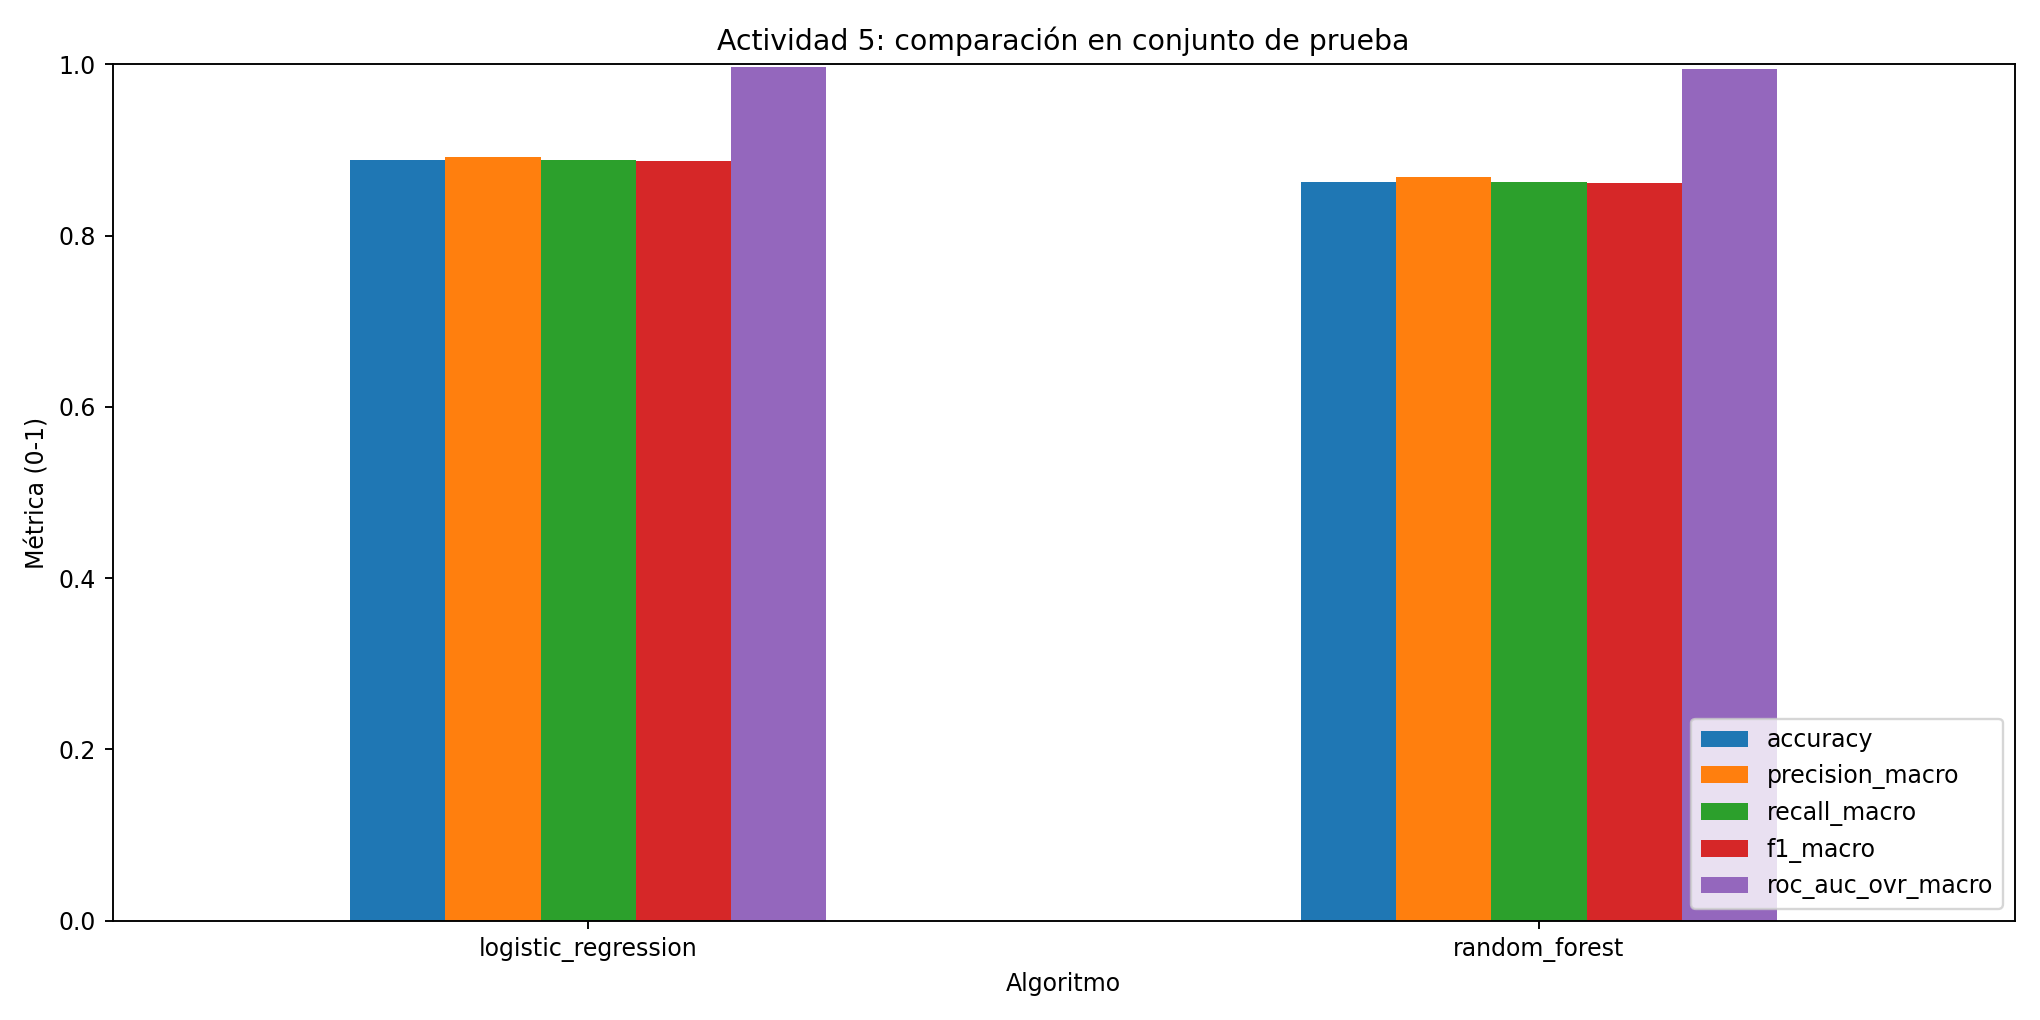

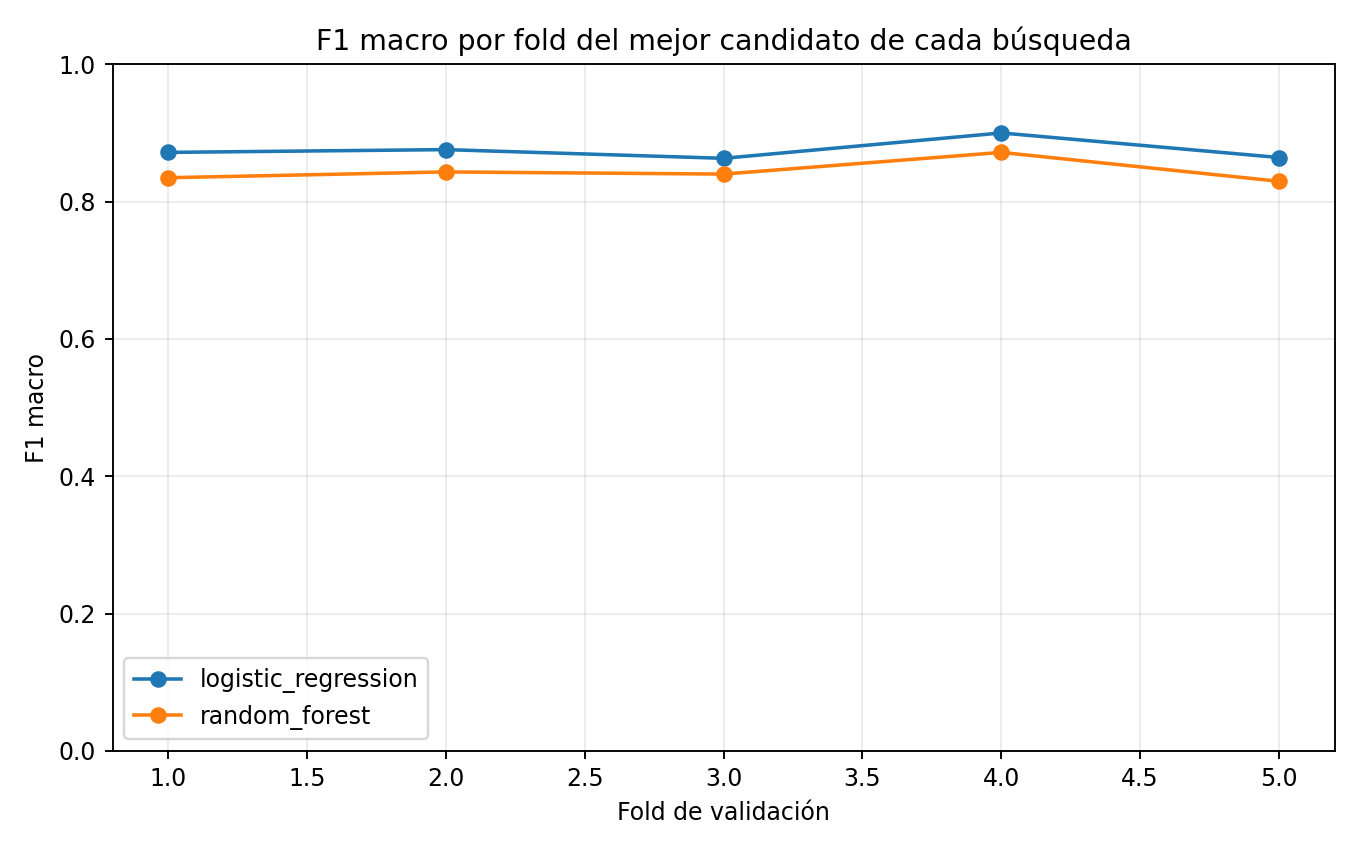

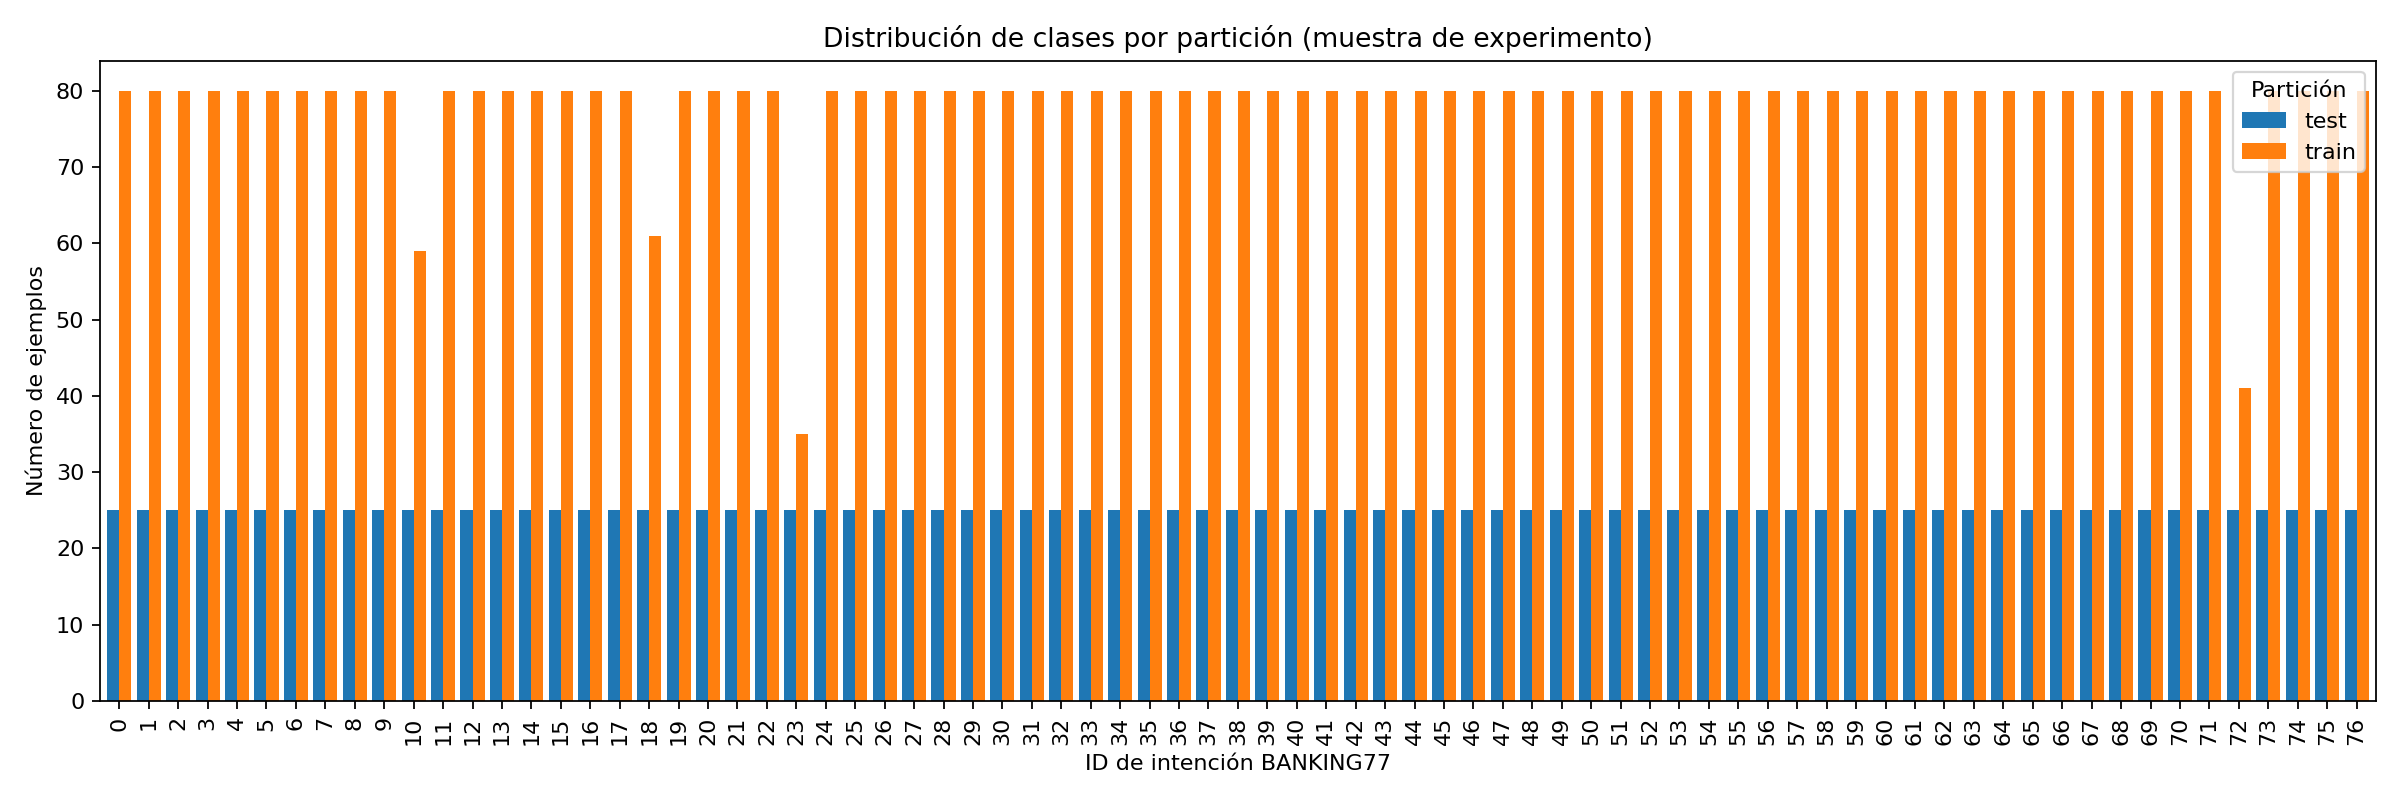

In [9]:
from IPython.display import display, Image
for fname in ["results/model_comparison.png", "results/cv_f1_by_fold.png", "results/class_distribution.png"]:
    if Path(fname).exists():
        display(Image(filename=fname))

In [10]:
# Verificación de resultados

results_dir = ROOT / "results"

# 1. Comparación de los modelos
comparison_file = results_dir / "model_comparison.csv"

if comparison_file.exists():
    comparison = pd.read_csv(comparison_file)
    display(comparison)
else:
    print("No se encontró model_comparison.csv")

# 2. Comparación estadística
stats_file = results_dir / "statistical_comparison.json"

if stats_file.exists():
    stats = json.loads(stats_file.read_text(encoding="utf-8"))
    print("\nComparación estadística:")
    print(json.dumps(stats, indent=2, ensure_ascii=False))

# 3. Archivos generados
print("\nArchivos disponibles en results/:")
for file in sorted(results_dir.iterdir()):
    print(file.name)

,model,best_params,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_macro_fold_scores,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,fit_search_seconds,embedding_seconds,run_id
0,logistic_regression,"{""C"": 10.0, ""class_weight"": ""None""}",0.874979,0.013379,"[0.8717337849727189, 0.8757624847073091, 0.863...",0.887792,0.89196,0.887792,0.887280,0.997284,92.608066,3.590748,259a78d34bd147acb2db6f9053144d6b
1,random_forest,"{""max_depth"": ""None"", ""min_samples_leaf"": 1, ""...",0.843913,0.014664,"[0.8348290685995275, 0.8432781891947454, 0.840...",0.862857,0.86823,0.862857,0.861592,0.994047,1149.752939,3.590748,f362ac02b15646ca91ac659413295395



Comparación estadística:
{
  "model_a": "logistic_regression",
  "model_b": "random_forest",
  "paired_test": "Exact McNemar test on held-out accuracy errors",
  "model_a_correct_model_b_wrong": 90,
  "model_a_wrong_model_b_correct": 42,
  "mcnemar_exact_p_value": 3.573574653630987e-05,
  "alpha": 0.05,
  "mcnemar_interpretation": "significant difference",
  "cv_test": "paired Wilcoxon signed-rank test on 5 best-grid fold scores; exploratory due to small number of folds",
  "wilcoxon_statistic": 0.0,
  "wilcoxon_p_value": 0.0625,
  "caution": "The same CV folds were used to select hyperparameters; treat CV significance as exploratory. McNemar compares paired test correctness only and does not establish operational superiority."
}

Archivos disponibles en results/:
README.md
actividad4_referencia_modelos.csv
class_distribution.csv
class_distribution.png
classification_report_logistic_regression.csv
classification_report_random_forest.csv
confusion_matrix_logistic_regression.csv
confusi

## 3. Revisar el panel MLflow

Ejecuta la siguiente celda. Si estás en Colab, abre el enlace que genera; si ejecutas localmente, visita `http://127.0.0.1:5000`. Para las evidencias, captura la tabla de experimentos y los detalles de las dos ejecuciones después de comprobar que muestran parámetros, métricas y artefactos reales.


In [11]:
import subprocess, time, socket
# No inicia una segunda UI si el puerto ya está ocupado.
def port_open(host="127.0.0.1", port=5000):
    with socket.socket() as sock:
        return sock.connect_ex((host, port)) == 0
if not port_open():
    mlflow_process = subprocess.Popen([sys.executable, "-m", "mlflow", "ui", "--backend-store-uri", str(ROOT / "mlruns"), "--host", "0.0.0.0", "--port", "5000"], stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
    time.sleep(3)
try:
    from google.colab import output
    display_link = output.eval_js("google.colab.kernel.proxyPort(5000)")
    print("Panel MLflow de Colab:", display_link)
except Exception:
    print("Panel MLflow local: http://127.0.0.1:5000")


Panel MLflow de Colab: https://5000-gpu-t4-s-kkb-ass1c1-27cejk0pmb57w-c.asia-southeast1-1.prod.colab.dev
